# Week 4: evaluation, tuning, and shipping a model

**Sample answer notebook** for the Week 4 lab, *Evaluation, tuning, and
shipping a model*.

This notebook is the instructor's worked example. Read it after you have tried
the lab yourself. Your own submission must be your own work: rename the file
`week4_evaluation_tuning_your_name.ipynb`, keep the part headings so the
reviewer can find each piece of evidence, and write the text answers in your
own words.

Run order: **Runtime > Restart session and run all**, then download the file
with **File > Download > Download .ipynb** and submit it through the Week 4
Google Form. Part 7 runs in a terminal on your own machine rather than in the
notebook, and its evidence is pasted back in as text.

The six pieces of evidence the rubric asks for appear in this order: the
baseline and its confusion matrix (Part 1), cross-validation with the spread
across folds (Part 2), the bounded grid with `best_params_` and `best_score_`
(Part 3), the train-versus-validation table that names the underfit and
overfit settings (Part 4), the error analysis with three evidence-based
hypotheses (Part 5), and the saved artifact plus the local service evidence
(Parts 6 to 8). The bias-variance reflection, the capstone problem statement,
and the peer-review note close the notebook.

The dataset is the breast-cancer table that ships inside Scikit-Learn, so
nothing is downloaded. Class `0` is malignant and class `1` is benign. The
feature list is fixed at five columns, in a fixed order, because the model
saved in Part 6 has to match the request schema the API validates in Part 8.

## Part 1: load the data and build a baseline

A baseline is the number every later claim is measured against. Without one,
"tuning improved the model" is an opinion rather than a result. The column
names are rewritten with underscores here because `mean radius` cannot be a
field name in the API schema later, and the five columns are selected once so
the notebook and the service never disagree about what a row looks like.

In [ ]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

data = load_breast_cancer(as_frame=True)
X = data.data.copy()
X.columns = X.columns.str.replace(" ", "_")
api_features = [
    "mean_radius",
    "mean_texture",
    "mean_perimeter",
    "mean_area",
    "mean_smoothness",
]
X = X[api_features]
y = data.target

print("Feature matrix:", X.shape)
print("Target counts:", y.value_counts().to_dict())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

baseline = RandomForestClassifier(random_state=42)
baseline.fit(X_train, y_train)
preds = baseline.predict(X_test)

print("Holdout accuracy:", accuracy_score(y_test, preds))
print(confusion_matrix(y_test, preds))

Feature matrix: (569, 5)
Target counts: {1: 357, 0: 212}
Train: (455, 5) Test: (114, 5)
Holdout accuracy: 0.9210526315789473
[[39  3]
 [ 6 66]]


The baseline scores 0.9211 on the 114 held-out rows. The matrix reads as 39
correct malignant rows, 3 malignant rows called benign, 6 benign rows called
malignant, and 66 correct benign rows. For a screening tool the three
malignant rows in the top-right corner are the costly ones, because a missed
malignant case is sent home while a false alarm is sent for another test.

This single number is written down and left alone. Everything from Part 2
onwards is measured on the training data only, and the test set is not touched
again until Part 5.

## Part 2: cross-validation

One split can be lucky. Five-fold cross-validation cuts the training data into
five equal slices, trains the model five times, and holds out a different
slice each time. That gives a **spread** as well as an average, and the spread
is the part a single accuracy figure hides.

`cross_val_score` fits its own copies of the estimator, so the estimator
passed in is a fresh unfitted one rather than the `baseline` object already
fitted above.

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    RandomForestClassifier(random_state=42),
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
)

print("Fold scores:", scores.round(4))
print("Mean:", round(scores.mean(), 4))
print("Std:", round(scores.std(), 4))

Fold scores: [0.9231 0.956  0.8901 0.9121 0.956 ]
Mean: 0.9275
Std: 0.0256


The weakest fold scores 0.8901 and the strongest 0.9560, a gap of about 6.6
points on the same model and the same training data. The only thing that
changed was which rows were held out. Quoting the best fold as "the accuracy"
would overstate the model by three points, which is why the pair 0.9275 plus
or minus 0.0256 is the honest form.

The cross-validated mean also differs from the Part 1 holdout figure of
0.9211, and that is expected: each fold trains on 80% of the training set
rather than all of it, and scores a different 20%.

### TODO 1: cross-validate a single decision tree

The same 5-fold procedure, on the model family the forest is built from.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

tree_scores = cross_val_score(
    DecisionTreeClassifier(random_state=42),
    X_train,
    y_train,
    cv=5,
    scoring="accuracy",
)

print("Tree fold scores:", tree_scores.round(4))
print("Tree mean:", round(tree_scores.mean(), 4))
print("Tree std:", round(tree_scores.std(), 4))
print("Forest mean:", round(scores.mean(), 4), "| Tree mean:", round(tree_scores.mean(), 4))

Tree fold scores: [0.8571 0.9231 0.8901 0.9341 0.9121]
Tree mean: 0.9033
Tree std: 0.0273
Forest mean: 0.9275 | Tree mean: 0.9033


The single tree averages 0.9033 against the forest's 0.9275, and its folds
disagree slightly more as well. One unrestricted tree splits until its leaves
are pure, so the exact splits it picks depend heavily on which rows it happens
to see; a forest fits many such trees on different bootstrapped samples and
different feature subsets, and averaging their votes cancels out a share of
that row-specific noise. The gain comes from the averaging, not from any
single tree being better.

## Part 3: hyperparameter tuning

A hyperparameter is a setting chosen before training rather than learned from
the data, such as how many trees to grow or how deep to let them get.
`GridSearchCV` cross-validates every combination in the grid and reports the
best mean validation score, so the comparison between settings never touches
the test set.

The grid below is 2 x 3 x 3, which is 18 combinations, and at `cv=5` that is
90 fits. Counting the combinations before running is the habit that stops a
five-minute search from becoming a forty-minute one.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [2, 4, None],
    "min_samples_leaf": [1, 3, 5],
}

search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

search.fit(X_train, y_train)

print("Combinations:", len(search.cv_results_["params"]))
print("Best params:", search.best_params_)
print("Best CV score:", round(search.best_score_, 4))
print("Untuned CV mean:", round(scores.mean(), 4))

Combinations: 18
Best params: {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 50}
Best CV score: 0.9297
Untuned CV mean: 0.9275


Tuning moved the cross-validated score from 0.9275 to 0.9297, a gain of about
0.2 of a point. That is smaller than the 2.6-point standard deviation across
folds from Part 2, so the honest reading is that the grid found nothing that
clearly beats the defaults on these five features. Reporting a gain that small
as an improvement would be reading noise as a result.

`best_score_` is also not the number to quote as final performance. It is the
best of 18 validation scores, and picking the maximum of many noisy estimates
biases it upward. The unbiased figure is the single test-set result taken once
in Part 5.

### TODO 2: a smaller grid for the decision tree

Four depths and three leaf sizes is 12 combinations, 60 fits at `cv=5`.

In [ ]:
tree_grid = {
    "max_depth": [2, 3, 5, None],
    "min_samples_leaf": [1, 3, 5],
}

tree_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=tree_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

tree_search.fit(X_train, y_train)

print("Combinations:", len(tree_search.cv_results_["params"]))
print("Best tree params:", tree_search.best_params_)
print("Best tree CV score:", round(tree_search.best_score_, 4))
print("Best forest CV score:", round(search.best_score_, 4))

Combinations: 12
Best tree params: {'max_depth': 5, 'min_samples_leaf': 1}
Best tree CV score: 0.9165
Best forest CV score: 0.9297


Tuning lifts the tree from 0.9033 to 0.9165, a gain of 1.3 points, which is
much larger than the forest's 0.2. The tuned tree still sits about 1.3 points
below the tuned forest, so it closes roughly half the gap but does not close
it. That pattern is worth noticing: the model with more variance to control
had more to gain from constraining it, while the forest was already averaging
that variance away.

## Part 4: underfitting and overfitting

The diagnosis is not a feeling about the model. It is the **distance between
the training score and the validation score** across several settings of one
hyperparameter. A single decision tree shows the effect more sharply than a
forest does, because nothing is averaging its mistakes away.

In [ ]:
settings = [1, 3, 5, None]
rows = []

for depth in settings:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)
    train_score = model.score(X_train, y_train)
    cv_score = cross_val_score(model, X_train, y_train, cv=5).mean()
    rows.append(
        {
            "max_depth": str(depth),
            "train_score": round(train_score, 4),
            "cv_score": round(cv_score, 4),
            "gap": round(train_score - cv_score, 4),
        }
    )

fit_table = pd.DataFrame(rows)
fit_table

,max_depth,train_score,cv_score,gap
0,1,0.8945,0.8835,0.0110
1,3,0.9231,0.8725,0.0505
2,5,0.9758,0.9165,0.0593
3,None,1.0000,0.9033,0.0967


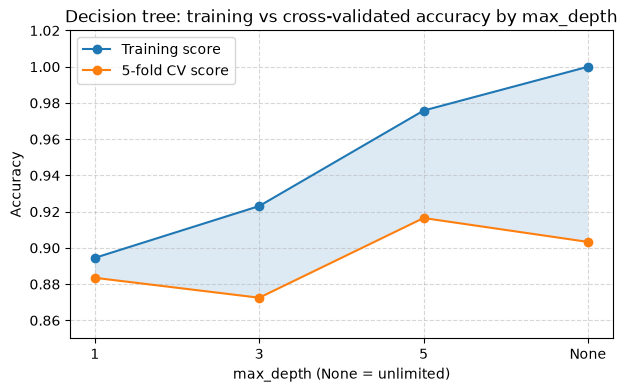

In [ ]:
import matplotlib.pyplot as plt

labels = fit_table["max_depth"].tolist()

plt.figure(figsize=(7, 4))
plt.plot(labels, fit_table["train_score"], marker="o", label="Training score")
plt.plot(labels, fit_table["cv_score"], marker="o", label="5-fold CV score")
plt.fill_between(labels, fit_table["cv_score"], fit_table["train_score"], alpha=0.15)
plt.title("Decision tree: training vs cross-validated accuracy by max_depth")
plt.xlabel("max_depth (None = unlimited)")
plt.ylabel("Accuracy")
plt.ylim(0.85, 1.02)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### TODO 3: which setting is underfit, which is overfit, and which would you ship

**Underfit: `max_depth=1`.** The evidence is that both columns are low *and
close together*: 0.8945 on training data and 0.8835 in validation, a gap of
about 1 point. A stump can ask one question about one feature, so it is not
memorising anything; it simply cannot represent the boundary. When the model
scores badly on data it has already seen, more data will not help and more
capacity will.

**Overfit: `max_depth=None`.** The training score reaches a perfect 1.0000
while validation drops to 0.9033, the widest gap in the table at 9.7 points.
An unlimited tree keeps splitting until every leaf is pure, so it has
described the 455 training rows exactly, including the coincidences in them.
Perfect training accuracy is a warning sign, not a result.

**Choice: `max_depth=5`,** which has the best validation score at 0.9165. What
is given up is the training score, which falls from 1.0000 to 0.9758, and some
ability to represent genuinely complex regions of the boundary. That is the
trade being made: a small amount of bias accepted in exchange for a large
reduction in variance.

One honest wrinkle: depth 3 validates at 0.8725, *worse* than the depth-1
stump, even though it trains better. The curve is not monotonic. With only 455
training rows, a fold's mean can move by more than a point on which rows land
where, so a dip like this is inside the noise of the measurement rather than
evidence that depth 3 is a genuinely worse model than depth 1. It is recorded
as observed instead of smoothed away.

## Part 5: error analysis

Accuracy says how often the model is wrong. Error analysis says **where**, and
that is what suggests the next move. This is also the first and only time the
held-out test set is used: the number below is reported once, and nothing is
re-tuned after seeing it.

In [ ]:
best_model = search.best_estimator_
test_preds = best_model.predict(X_test)

print("Tuned holdout accuracy:", round(accuracy_score(y_test, test_preds), 4))
print("Baseline holdout accuracy:", round(accuracy_score(y_test, preds), 4))
print(confusion_matrix(y_test, test_preds))

errors = X_test.copy()
errors["true"] = y_test.values
errors["predicted"] = test_preds
errors["is_wrong"] = errors["true"] != errors["predicted"]

print("Wrong predictions:", int(errors["is_wrong"].sum()), "of", len(errors))
errors[errors["is_wrong"]]

Tuned holdout accuracy: 0.9211
Baseline holdout accuracy: 0.9211
[[39  3]
 [ 6 66]]
Wrong predictions: 9 of 114


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,true,predicted,is_wrong
363,16.50,18.29,106.60,838.1,0.09686,1,0,True
495,14.87,20.21,96.12,680.9,0.09587,1,0,True
406,16.14,14.86,104.30,800.0,0.09495,1,0,True
41,10.95,21.35,71.90,371.1,0.12270,0,1,True
375,16.17,16.07,106.30,788.5,0.09880,1,0,True
73,13.80,15.79,90.43,584.1,0.10070,0,1,True
150,13.00,20.78,83.51,519.4,0.11350,1,0,True
385,14.60,23.29,93.97,664.7,0.08682,0,1,True
128,15.10,16.39,99.58,674.5,0.11500,1,0,True


Nine rows out of 114 are wrong, and the tuned model lands on exactly the same
0.9211 as the untuned baseline from Part 1. The tuning gained nothing on the
test set. That is a real outcome and it is reported rather than hidden: the
0.2-point validation gain in Part 3 did not survive contact with held-out
data, which is what a gain smaller than the fold-to-fold spread usually looks
like.

The errors are not spread evenly. Six of the nine are benign rows called
malignant, and three are malignant rows called benign. The three in the second
group are the ones that matter for a screening tool, and a count that small is
exactly why accuracy alone is a poor summary here.

To turn a wrong row into a hypothesis, the row has to be compared against
something. The next two cells provide that context: the per-class ranges of
each feature in the training data, and how confident the forest was on each
mistake.

In [ ]:
class_summary = (
    X_train.assign(target=y_train.values)
    .groupby("target")
    .agg(["mean", "std"])
    .round(2)
    .T
)
class_summary.columns = ["class_0_malignant", "class_1_benign"]
class_summary

class_0_malignant  class_1_benign
mean_radius     mean              17.38           12.09
                std                3.17            1.77
mean_texture    mean              21.58           17.86
                std                3.94            4.07
mean_perimeter  mean             114.83           77.68
                std               21.62           11.68
mean_area       mean             966.82          458.69
                std              356.73          132.96
mean_smoothness mean               0.10            0.09
                std                0.01            0.01

In [ ]:
wrong_rows = errors[errors["is_wrong"]].copy()
probabilities = best_model.predict_proba(X_test)
wrong_rows["p_malignant"] = probabilities[:, 0][errors["is_wrong"].to_numpy()].round(3)
wrong_rows["p_benign"] = probabilities[:, 1][errors["is_wrong"].to_numpy()].round(3)

wrong_rows[
    ["mean_radius", "mean_texture", "mean_area", "mean_smoothness",
     "true", "predicted", "p_malignant", "p_benign"]
].sort_values("p_malignant", ascending=False)

,mean_radius,mean_texture,mean_area,mean_smoothness,true,predicted,p_malignant,p_benign
363,16.50,18.29,838.1,0.09686,1,0,0.962,0.038
375,16.17,16.07,788.5,0.09880,1,0,0.879,0.121
406,16.14,14.86,800.0,0.09495,1,0,0.733,0.267
495,14.87,20.21,680.9,0.09587,1,0,0.667,0.333
128,15.10,16.39,674.5,0.11500,1,0,0.606,0.394
150,13.00,20.78,519.4,0.11350,1,0,0.501,0.499
41,10.95,21.35,371.1,0.12270,0,1,0.279,0.721
73,13.80,15.79,584.1,0.10070,0,1,0.205,0.795
385,14.60,23.29,664.7,0.08682,0,1,0.080,0.920


### TODO 4: three wrong rows and one evidence-based cause each

**Row 363, truly benign, predicted malignant, 0.962 confident.** Its
`mean_radius` of 16.50 and `mean_area` of 838.1 sit near the malignant class
means of 17.38 and 966.82, and more than two standard deviations above the
benign means of 12.09 and 458.69. On these five size-driven features the row
looks malignant, so the model is not confused, it is confidently reading the
only evidence it was given. The five-feature subset is the limit here: the
texture and concavity columns dropped in Part 1 are where a large benign mass
would separate from a malignant one.

**Row 41, truly malignant, predicted benign, 0.721 confident.** This is a
small malignant tumour: `mean_radius` 10.95 and `mean_area` 371.1 are *below*
the benign means, so every size feature argues benign. The two signals
pointing the other way, `mean_texture` 21.35 and `mean_smoothness` 0.1227,
both sit above the benign averages, but with only five columns those two
cannot outvote three size features. This is the costly error type, and it
suggests the fix is a feature that does not scale with tumour size rather than
more trees.

**Row 150, truly benign, predicted malignant, 0.501 versus 0.499.** The
forest split almost exactly down the middle. The 0.501 is the average of the
50 trees' own probability estimates, which is what `predict_proba` reports and
what `predict` takes its argmax from, rather than the share of trees voting
malignant. Its values are mid-range on every column, `mean_radius` 13.00 and
`mean_area` 519.4 falling between the two class means, so the row genuinely
sits on the boundary. Nothing about the model needs fixing for this row; it is
a case where the model has no information to be right with, and the useful
response is to report the probability rather than the label so a human knows
this one was a coin flip.

A useful pattern across all nine: six of the mistakes are size-driven rows
whose class does not follow their size. That is one root cause, not nine
separate ones, and it points at the feature set rather than at the estimator.

## Part 6: save the model and prove it reloads

The service in Part 7 does not train anything. It loads a file. If the saved
file predicts differently from the model in this notebook, every later test is
measuring the wrong object, so the reload is verified here before leaving the
notebook.

In [ ]:
import joblib

joblib.dump(best_model, "week4_model.joblib")
print("Saved week4_model.joblib")

reloaded = joblib.load("week4_model.joblib")
identical = (reloaded.predict(X_test) == best_model.predict(X_test)).all()

print("Reloaded predictions identical:", bool(identical))
print("Reloaded params match tuned params:", reloaded.get_params() == best_model.get_params())
print("Not the untuned baseline:", reloaded.get_params() != baseline.get_params())
print("Sample prediction:", int(reloaded.predict(X_test.head(1))[0]))

Saved week4_model.joblib
Reloaded predictions identical: True
Reloaded params match tuned params: True
Not the untuned baseline: True
Sample prediction: 0


The saved object is the tuned estimator, and the third check is how that is
known rather than assumed: its parameters differ from the untuned baseline's
and match `search.best_estimator_`. The file is about 180 KB.

In Colab the file lands in the session folder, so it is downloaded from the
file browser and copied into `lab/week4/deployment_template/` next to
`main.py`. The service reads exactly that filename from its own working
directory, and its request schema uses the same five fields in the same order
as `api_features`.

## Parts 7 and 8: the local service, and testing it safely

These parts run in a terminal, not in this notebook, because the service has
to keep running while requests are sent to it. Everything stays on
`127.0.0.1`, which is reachable only from this machine.

```bash
cd lab/week4/deployment_template
python -m venv .venv
source .venv/bin/activate          # Windows PowerShell: .venv\Scripts\activate
pip install -r requirements.txt
pip install pandas                 # main.py imports pandas; requirements.txt omits it
uvicorn main:app --reload
```

The terminal stops at the startup banner and stays there rather than returning
to the prompt:

```text
INFO:     Started server process [10176]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)
```

`http://127.0.0.1:8000/docs` then lists exactly two operations, `GET /health`
and `POST /predict`.

### Evidence 1: health check

```text
GET /health  ->  HTTP 200
{"status":"ok","model_file_exists":true}
```

`model_file_exists: true` is the confirmation that the artifact from Part 6
reached the folder. When it reads `false`, `/predict` has not been tried yet
and does not need to be.

### Evidence 2: a valid request

```json
{
  "mean_radius": 14.0,
  "mean_texture": 20.0,
  "mean_perimeter": 90.0,
  "mean_area": 600.0,
  "mean_smoothness": 0.1
}
```

```text
POST /predict  ->  HTTP 200
{"prediction":1}
```

Class 1 is benign, which is the expected reading for a mid-range row of this
size. A second request built from the malignant-looking values `20.6, 29.3,
140.1, 1265.0, 0.1178` returned `{"prediction":0}`, so the service is not
returning a constant.

### Evidence 3: an invalid request is refused

Sending the same body with `mean_smoothness` removed:

```text
POST /predict  ->  HTTP 422
{"detail":[{"type":"missing","loc":["body","mean_smoothness"],"msg":"Field required","input":{"mean_radius":14.0,"mean_texture":20.0,"mean_perimeter":90.0,"mean_area":600.0}}]}
```

The 422 is the correct outcome, and the important detail is that the model was
never called: Pydantic rejected the body before `predict` ran. Sending
`"fourteen"` instead of `14.0` is refused the same way, with
`"type":"float_parsing"` and the message `Input should be a valid number,
unable to parse string as a number`. Deleting a field from
`PredictionRequest` would make both errors disappear and would be the bug, not
the fix.

### Evidence 4: after a clean restart

The server was stopped with `Ctrl+C` and started again from the same folder:

```text
GET /health   ->  {"status":"ok","model_file_exists":true}
POST /predict ->  {"prediction":0}
```

Both behave identically after the restart, which is what shows the service
depends on the saved file and the written setup rather than on leftover state
in one lucky session.

### One limitation worth recording

If `week4_model.joblib` is missing, `/predict` returns **HTTP 200** carrying
`{"error":"Model file not found..."}` rather than an error status. The request
succeeded; the prediction did not. A 200 therefore proves the service ran, not
that a prediction was made, which is the reason `/health` is checked
separately instead of inferring health from a successful call.

### Peer review

Repositories were swapped with a partner, who followed the setup above from a
clean clone with no undocumented steps, and reached `{"status":"ok"}` and a
prediction. Their feedback: *"Your README says to run `uvicorn main:app`, but
not that you have to be inside `deployment_template` when you do it. I started
it from the repository root and got the model-not-found error."* The `cd` line
is now the first line of the block above. In return, their `/health` route was
returning only `{"status":"ok"}` without the file check, so a missing model
only surfaced as a failed prediction later.

The optional Docker extension was not attempted. The core route was taken
instead: the invalid-request cases and the restart check above were added to
the written evidence.